### Social Peer Matching & Isolation Detection (Clustering)
#
#### Objective
##### Use **unsupervised learning** to identify groups of students based on their social perception (belonging, loneliness, inclusion). The model detects **socially isolated students** and recommends group-based support activities.
#
#### Ethical Constraints
*   NO identification of specific peers
*   NO exposure of social relationships
*   Focus on **perception** (how students feel), not identity
*   Recommendations are for **environments** (clubs, groups, activities)
#
#### Why Clustering?
##### There's no "correct label" for social grouping — we don't know the true social clusters. Clustering discovers natural groupings in the data.

#### Section 1: Install and Import Libraries

In [1]:
# ============================================================
# SECTION 1: INSTALL AND IMPORT LIBRARIES
# ============================================================
# !pip install pandas numpy scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("=" * 60)
print("COLAB 6: SOCIAL PEER MATCHING & ISOLATION DETECTION")
print("=" * 60)

COLAB 6: SOCIAL PEER MATCHING & ISOLATION DETECTION


#### Section 2: Load and Inspect Data

In [2]:
# ============================================================
# SECTION 2: LOAD AND INSPECT DATA
# ============================================================
df = pd.read_csv('c3_intervention_dataset.csv')
print(f"Dataset shape: {df.shape}")
print(f"Students: {df['student_id'].nunique()}")
print(f"Weeks: {sorted(df['week'].unique())}")

Dataset shape: (1010, 18)
Students: 200
Weeks: [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12)]


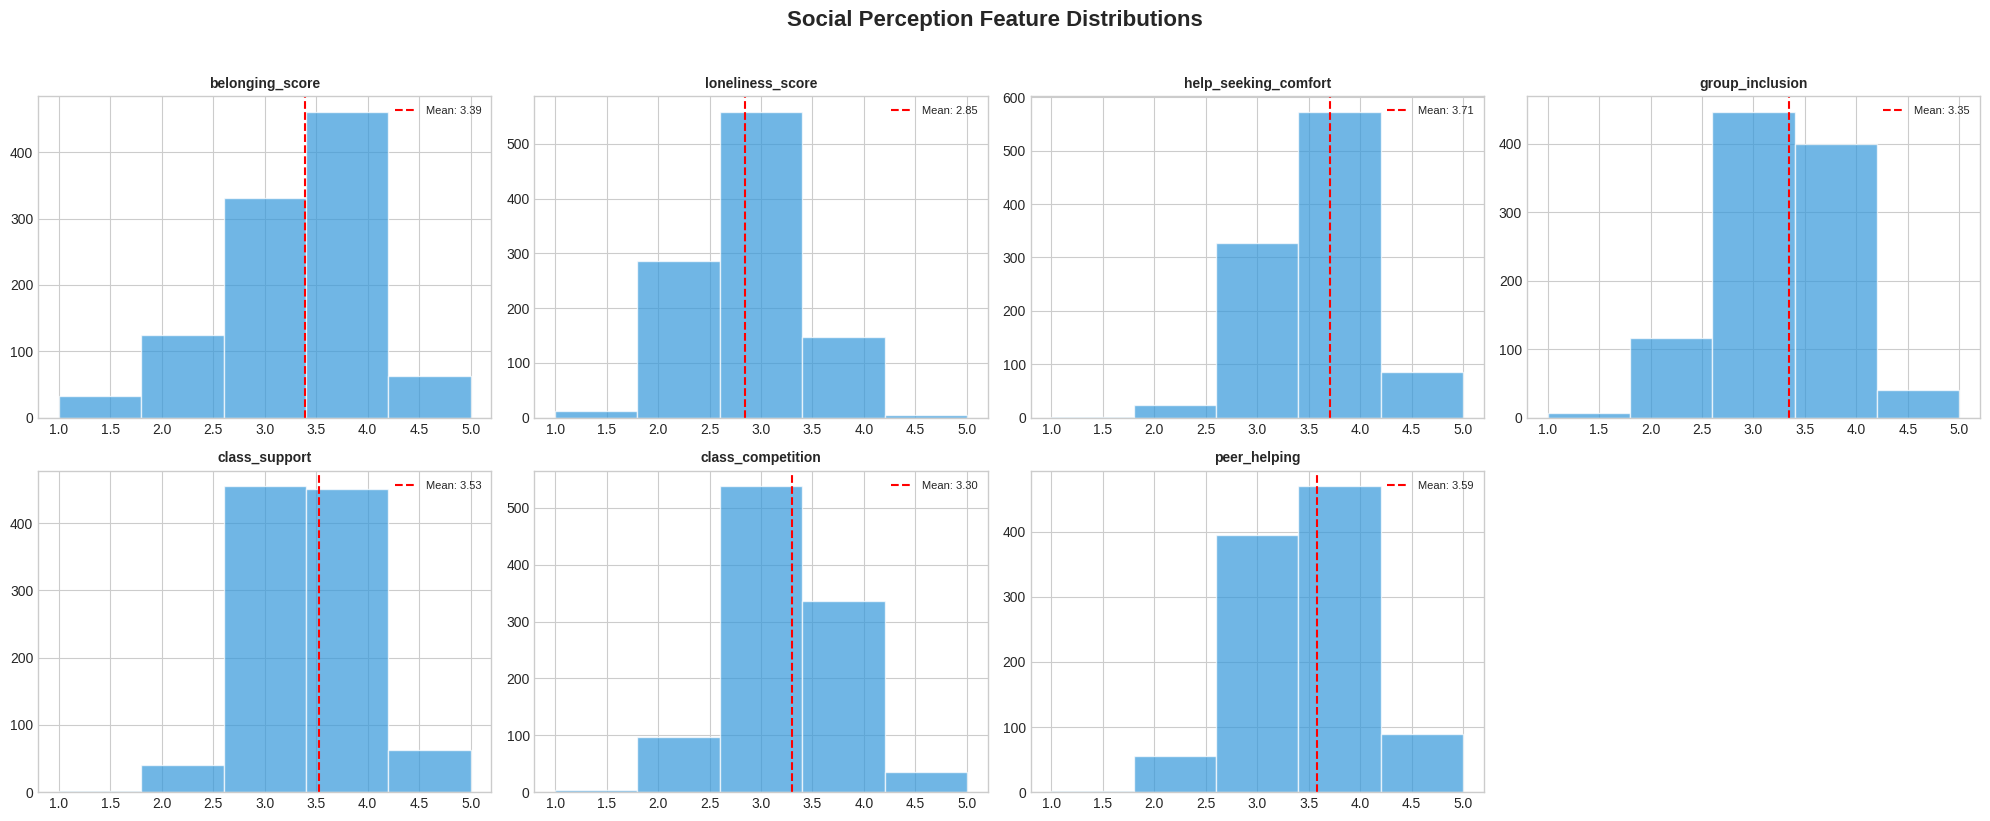

In [3]:
# ============================================================
# EDA CHART 1: SOCIAL PERCEPTION DISTRIBUTIONS
# ============================================================
social_features = ['belonging_score', 'loneliness_score', 'help_seeking_comfort',
                   'group_inclusion', 'class_support', 'class_competition', 'peer_helping']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()
for i, feat in enumerate(social_features):
    axes[i].hist(df[feat], bins=5, color='#3498db', alpha=0.7, edgecolor='white')
    axes[i].set_title(feat, fontweight='bold', fontsize=10)
    axes[i].axvline(df[feat].mean(), color='red', linestyle='--', linewidth=1.5,
                    label=f'Mean: {df[feat].mean():.2f}')
    axes[i].legend(fontsize=8)
axes[7].axis('off')

fig.suptitle('Social Perception Feature Distributions', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c6_chart1_social_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

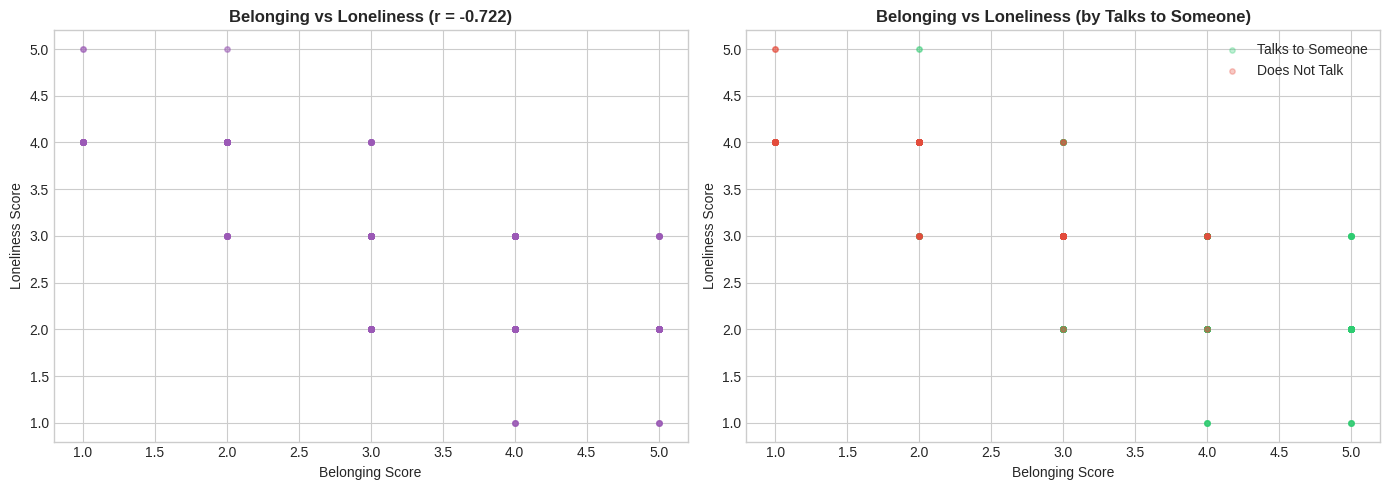

In [4]:
# ============================================================
# EDA CHART 2: BELONGING vs LONELINESS
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['belonging_score'], df['loneliness_score'], alpha=0.3, s=15, color='#9b59b6')
r = df['belonging_score'].corr(df['loneliness_score'])
axes[0].set_title(f'Belonging vs Loneliness (r = {r:.3f})', fontweight='bold')
axes[0].set_xlabel('Belonging Score')
axes[0].set_ylabel('Loneliness Score')

# Talks_to_someone impact
for val, color, label in [(1, '#2ecc71', 'Talks to Someone'), (0, '#e74c3c', 'Does Not Talk')]:
    mask = df['talks_to_someone'] == val
    axes[1].scatter(df.loc[mask, 'belonging_score'], df.loc[mask, 'loneliness_score'],
                    alpha=0.3, s=15, color=color, label=label)
axes[1].set_title('Belonging vs Loneliness (by Talks to Someone)', fontweight='bold')
axes[1].set_xlabel('Belonging Score')
axes[1].set_ylabel('Loneliness Score')
axes[1].legend()

plt.tight_layout()
plt.savefig('c6_chart2_belonging_vs_loneliness.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 3: Student-Level Aggregation & Feature Engineering
#
##### Since students have multiple survey responses across weeks, we aggregate to create a **single profile per student** for clustering.


In [5]:
# ============================================================
# SECTION 3: AGGREGATE TO STUDENT LEVEL
# ============================================================
print("\n" + "=" * 60)
print("SECTION 3: STUDENT-LEVEL AGGREGATION")
print("=" * 60)

# Aggregate features per student (mean and std across weeks)
agg_features = ['belonging_score', 'loneliness_score', 'help_seeking_comfort',
                'group_inclusion', 'has_support_person', 'talks_to_someone',
                'class_support', 'class_competition', 'peer_helping', 'break_frequency']

agg_dict = {}
for feat in agg_features:
    agg_dict[f'{feat}_mean'] = (feat, 'mean')
    agg_dict[f'{feat}_std'] = (feat, 'std')

# Also count total responses
agg_dict['survey_count'] = ('week', 'count')

student_df = df.groupby('student_id').agg(**agg_dict).reset_index()
student_df = student_df.fillna(0)  # std is NaN for single-response students

print(f"Student-level profiles: {student_df.shape}")
print(f"Features per student: {student_df.shape[1] - 1}")  # Exclude student_id


SECTION 3: STUDENT-LEVEL AGGREGATION
Student-level profiles: (200, 22)
Features per student: 21


In [6]:
# ============================================================
# FEATURE ENGINEERING (Clustering-Specific)
# ============================================================
print("\n--- Feature Engineering ---")

# Feature 1: Social Perception Score (net positive social feeling)
student_df['social_perception_score'] = (
    student_df['belonging_score_mean'] + student_df['group_inclusion_mean'] +
    student_df['help_seeking_comfort_mean'] - student_df['loneliness_score_mean']
) / 4
print(f"[+] social_perception_score (mean: {student_df['social_perception_score'].mean():.2f})")

# Feature 2: Isolation Index (higher = more isolated)
student_df['isolation_index'] = (
    (5 - student_df['belonging_score_mean']) +
    student_df['loneliness_score_mean'] +
    (5 - student_df['group_inclusion_mean'])
)
print(f"[+] isolation_index (mean: {student_df['isolation_index'].mean():.2f})")

# Feature 3: Support Availability
student_df['support_availability'] = (
    student_df['has_support_person_mean'] + student_df['talks_to_someone_mean']
)
print(f"[+] support_availability (mean: {student_df['support_availability'].mean():.2f})")

# Feature 4: Class Environment
student_df['class_environment'] = (
    student_df['class_support_mean'] + student_df['peer_helping_mean'] -
    student_df['class_competition_mean']
)
print(f"[+] class_environment (mean: {student_df['class_environment'].mean():.2f})")

# Feature 5: Social Stability (how volatile are their social scores)
student_df['social_stability'] = student_df['belonging_score_std'] + student_df['loneliness_score_std']
print(f"[+] social_stability (mean: {student_df['social_stability'].mean():.2f})")

# Feature 6: Loneliness Trend (slope across weeks)
def compute_slope(group, col):
    if len(group) < 2:
        return 0
    x = np.arange(len(group))
    y = group[col].values
    slope, _, _, _, _ = np.polyfit(x, y, 1, full=False, cov=False), 0, 0, 0, 0
    return np.polyfit(x, y, 1)[0]

loneliness_trends = df.sort_values('week').groupby('student_id').apply(
    lambda g: compute_slope(g, 'loneliness_score'), include_groups=False
).reset_index()
loneliness_trends.columns = ['student_id', 'loneliness_trend']
student_df = student_df.merge(loneliness_trends, on='student_id', how='left')
student_df['loneliness_trend'] = student_df['loneliness_trend'].fillna(0)
print(f"[+] loneliness_trend (mean: {student_df['loneliness_trend'].mean():.3f})")

print(f"\nFinal student profile: {student_df.shape}")


--- Feature Engineering ---
[+] social_perception_score (mean: 1.90)
[+] isolation_index (mean: 6.13)
[+] support_availability (mean: 1.70)
[+] class_environment (mean: 3.81)
[+] social_stability (mean: 1.03)
[+] loneliness_trend (mean: -0.023)

Final student profile: (200, 28)


#### Section 4: Prepare Clustering Features and Scale

In [7]:
# ============================================================
# SECTION 4: PREPARE CLUSTERING FEATURES & SCALE
# ============================================================
print("\n" + "=" * 60)
print("SECTION 4: PREPARE & SCALE FEATURES")
print("=" * 60)

# Select features for clustering
cluster_features = [
    'belonging_score_mean', 'loneliness_score_mean', 'help_seeking_comfort_mean',
    'group_inclusion_mean', 'has_support_person_mean', 'talks_to_someone_mean',
    'class_support_mean', 'peer_helping_mean',
    'social_perception_score', 'isolation_index', 'support_availability',
    'class_environment', 'social_stability', 'loneliness_trend'
]

X_cluster = student_df[cluster_features].copy()

# StandardScaler (critical for clustering — distance-based algorithms need normalization)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_cluster), columns=cluster_features, index=X_cluster.index)

print(f"Clustering features: {X_scaled.shape[1]}")
print(f"Students: {X_scaled.shape[0]}")

# PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
student_df['pca_1'] = X_pca[:, 0]
student_df['pca_2'] = X_pca[:, 1]

print(f"\nPCA variance explained: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total: {sum(pca.explained_variance_ratio_)*100:.1f}%")

print("\n" + "=" * 60)
print("PART 1 COMPLETE: Student profiles ready for clustering!")
print("Proceed to Part 2 for Clustering Models & Evaluation.")
print("=" * 60)



SECTION 4: PREPARE & SCALE FEATURES
Clustering features: 14
Students: 200

PCA variance explained: PC1=69.2%, PC2=8.2%
Total: 77.4%

PART 1 COMPLETE: Student profiles ready for clustering!
Proceed to Part 2 for Clustering Models & Evaluation.


#### Section 5: Model Training

In [8]:
# ============================================================
# SETUP (Run after Part 1 or standalone)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage
import joblib
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

# --- Recreate pipeline ---
df = pd.read_csv('c3_intervention_dataset.csv')
agg_features = ['belonging_score', 'loneliness_score', 'help_seeking_comfort',
                'group_inclusion', 'has_support_person', 'talks_to_someone',
                'class_support', 'class_competition', 'peer_helping', 'break_frequency']

agg_dict = {f'{f}_mean': (f, 'mean') for f in agg_features}
agg_dict.update({f'{f}_std': (f, 'std') for f in agg_features})
agg_dict['survey_count'] = ('week', 'count')
student_df = df.groupby('student_id').agg(**agg_dict).reset_index().fillna(0)

student_df['social_perception_score'] = (student_df['belonging_score_mean'] + student_df['group_inclusion_mean'] + student_df['help_seeking_comfort_mean'] - student_df['loneliness_score_mean']) / 4
student_df['isolation_index'] = (5 - student_df['belonging_score_mean']) + student_df['loneliness_score_mean'] + (5 - student_df['group_inclusion_mean'])
student_df['support_availability'] = student_df['has_support_person_mean'] + student_df['talks_to_someone_mean']
student_df['class_environment'] = student_df['class_support_mean'] + student_df['peer_helping_mean'] - student_df['class_competition_mean']
student_df['social_stability'] = student_df['belonging_score_std'] + student_df['loneliness_score_std']

def compute_slope(group, col):
    if len(group) < 2: return 0
    return np.polyfit(np.arange(len(group)), group[col].values, 1)[0]

trends = df.sort_values('week').groupby('student_id').apply(lambda g: compute_slope(g, 'loneliness_score'), include_groups=False).reset_index()
trends.columns = ['student_id', 'loneliness_trend']
student_df = student_df.merge(trends, on='student_id', how='left').fillna(0)

cluster_features = ['belonging_score_mean', 'loneliness_score_mean', 'help_seeking_comfort_mean',
    'group_inclusion_mean', 'has_support_person_mean', 'talks_to_someone_mean',
    'class_support_mean', 'peer_helping_mean',
    'social_perception_score', 'isolation_index', 'support_availability',
    'class_environment', 'social_stability', 'loneliness_trend']

X_cluster = student_df[cluster_features]
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_cluster), columns=cluster_features)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
student_df['pca_1'] = X_pca[:, 0]
student_df['pca_2'] = X_pca[:, 1]

print("=" * 60)
print("SECTION 5: CLUSTERING MODELS")
print("=" * 60)

SECTION 5: CLUSTERING MODELS



##################################################
# MODEL 1: K-MEANS CLUSTERING
##################################################


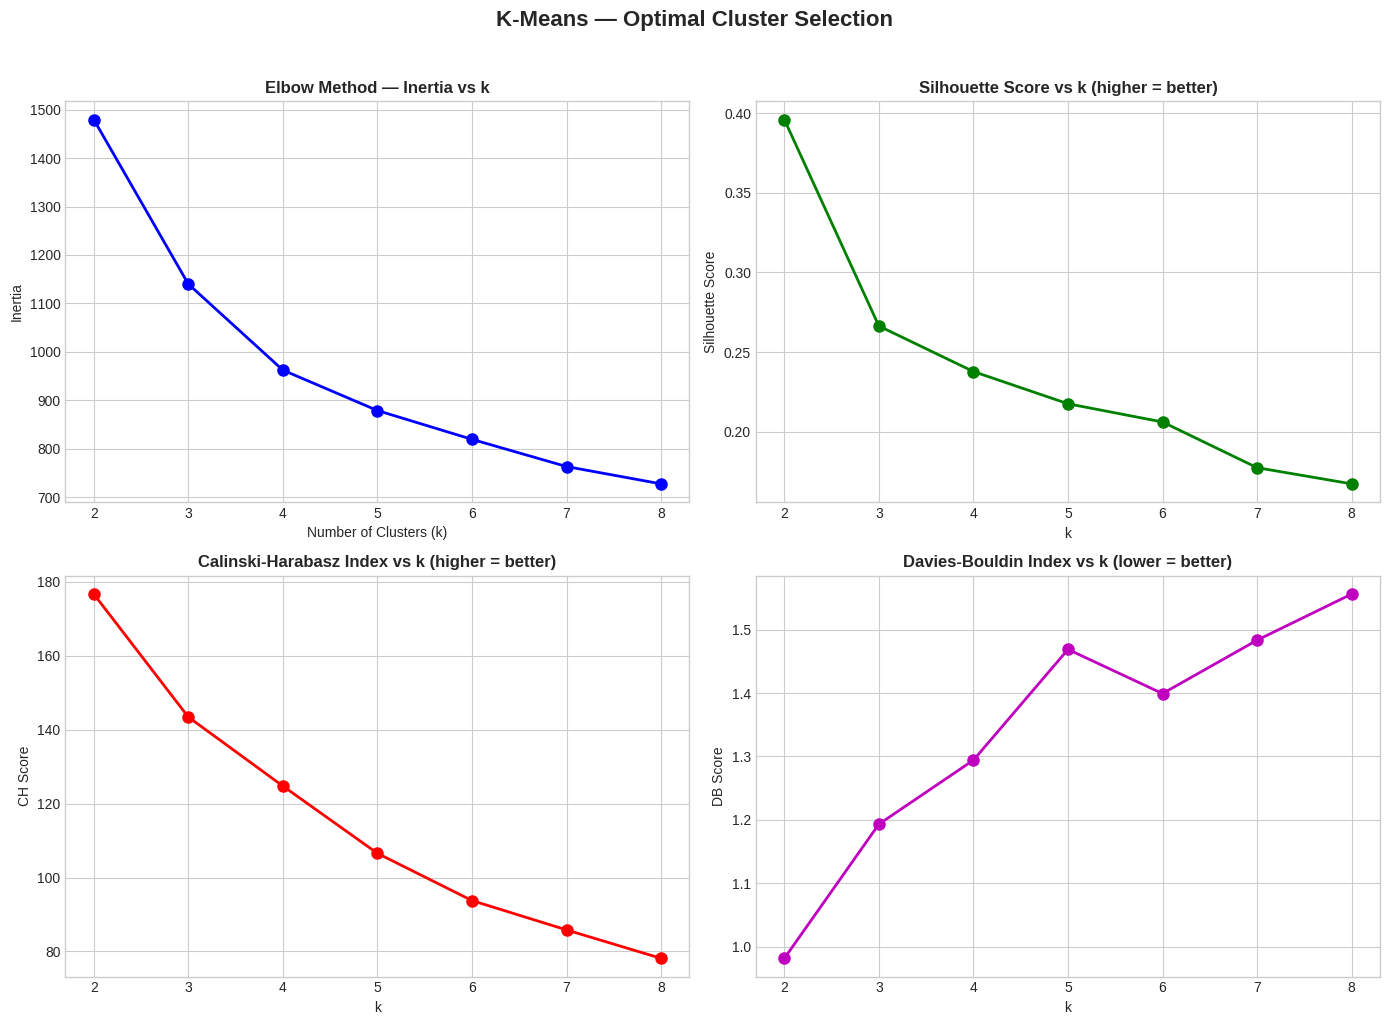


Optimal k = 2 (silhouette = 0.3959)

--- K-Means Cluster Distribution ---
kmeans_cluster
0     77
1    123
Name: count, dtype: int64


In [9]:
# ============================================================
# MODEL 1: K-MEANS — Elbow Method to find optimal k
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 1: K-MEANS CLUSTERING")
print("#" * 50)

# Test k = 2 to 8
k_range = range(2, 9)
inertias = []
silhouettes = []
ch_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow method
axes[0, 0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0, 0].set_title('Elbow Method — Inertia vs k', fontweight='bold')
axes[0, 0].set_xlabel('Number of Clusters (k)')
axes[0, 0].set_ylabel('Inertia')

# Silhouette
axes[0, 1].plot(k_range, silhouettes, 'go-', linewidth=2, markersize=8)
axes[0, 1].set_title('Silhouette Score vs k (higher = better)', fontweight='bold')
axes[0, 1].set_xlabel('k')
axes[0, 1].set_ylabel('Silhouette Score')

# Calinski-Harabasz
axes[1, 0].plot(k_range, ch_scores, 'ro-', linewidth=2, markersize=8)
axes[1, 0].set_title('Calinski-Harabasz Index vs k (higher = better)', fontweight='bold')
axes[1, 0].set_xlabel('k')
axes[1, 0].set_ylabel('CH Score')

# Davies-Bouldin
axes[1, 1].plot(k_range, db_scores, 'mo-', linewidth=2, markersize=8)
axes[1, 1].set_title('Davies-Bouldin Index vs k (lower = better)', fontweight='bold')
axes[1, 1].set_xlabel('k')
axes[1, 1].set_ylabel('DB Score')

fig.suptitle('K-Means — Optimal Cluster Selection', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c6_chart3_elbow_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Select optimal k (best silhouette)
optimal_k = list(k_range)[np.argmax(silhouettes)]
print(f"\nOptimal k = {optimal_k} (silhouette = {max(silhouettes):.4f})")

# Fit K-Means with optimal k
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
student_df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

print(f"\n--- K-Means Cluster Distribution ---")
print(student_df['kmeans_cluster'].value_counts().sort_index())

In [10]:
# ============================================================
# MODEL 2: DBSCAN (Density-Based)
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 2: DBSCAN")
print("#" * 50)

# DBSCAN finds clusters of varying shapes and identifies noise (outliers = isolated students)
dbscan = DBSCAN(eps=2.0, min_samples=5)
student_df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

n_clusters = len(set(student_df['dbscan_cluster'])) - (1 if -1 in student_df['dbscan_cluster'].values else 0)
n_noise = (student_df['dbscan_cluster'] == -1).sum()
print(f"DBSCAN found {n_clusters} clusters and {n_noise} noise points (potential isolates)")
print(student_df['dbscan_cluster'].value_counts().sort_index())


##################################################
# MODEL 2: DBSCAN
##################################################
DBSCAN found 1 clusters and 27 noise points (potential isolates)
dbscan_cluster
-1     27
 0    173
Name: count, dtype: int64


In [11]:
# ============================================================
# MODEL 3: AGGLOMERATIVE CLUSTERING
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 3: AGGLOMERATIVE CLUSTERING")
print("#" * 50)

agg_cluster = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
student_df['agg_cluster'] = agg_cluster.fit_predict(X_scaled)

print(f"Agglomerative Cluster Distribution:")
print(student_df['agg_cluster'].value_counts().sort_index())


##################################################
# MODEL 3: AGGLOMERATIVE CLUSTERING
##################################################
Agglomerative Cluster Distribution:
agg_cluster
0    135
1     65
Name: count, dtype: int64


In [12]:
# ============================================================
# MODEL 4: ISOLATION FOREST (Anomaly Detection)
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 4: ISOLATION FOREST (Anomaly Detection)")
print("#" * 50)

# Isolation Forest detects anomalous (isolated) students
iso_forest = IsolationForest(contamination=0.10, random_state=42)
student_df['isolation_flag'] = iso_forest.fit_predict(X_scaled)
# -1 = anomaly (isolated), 1 = normal
student_df['is_isolated'] = (student_df['isolation_flag'] == -1).astype(int)

n_isolated = student_df['is_isolated'].sum()
pct_isolated = n_isolated / len(student_df) * 100
print(f"Isolated students detected: {n_isolated} ({pct_isolated:.1f}%)")
print(f"\nIsolated students profile (mean values):")
iso_profile = student_df.groupby('is_isolated')[
    ['belonging_score_mean', 'loneliness_score_mean', 'group_inclusion_mean',
     'support_availability', 'isolation_index']
].mean().round(2)
print(iso_profile)


##################################################
# MODEL 4: ISOLATION FOREST (Anomaly Detection)
##################################################
Isolated students detected: 20 (10.0%)

Isolated students profile (mean values):
             belonging_score_mean  loneliness_score_mean  \
is_isolated                                                
0                            3.46                   2.81   
1                            2.72                   3.25   

             group_inclusion_mean  support_availability  isolation_index  
is_isolated                                                               
0                            3.39                  1.78             5.96  
1                            2.90                  0.97             7.64  


#### Section 6: Evaluation & Visualization

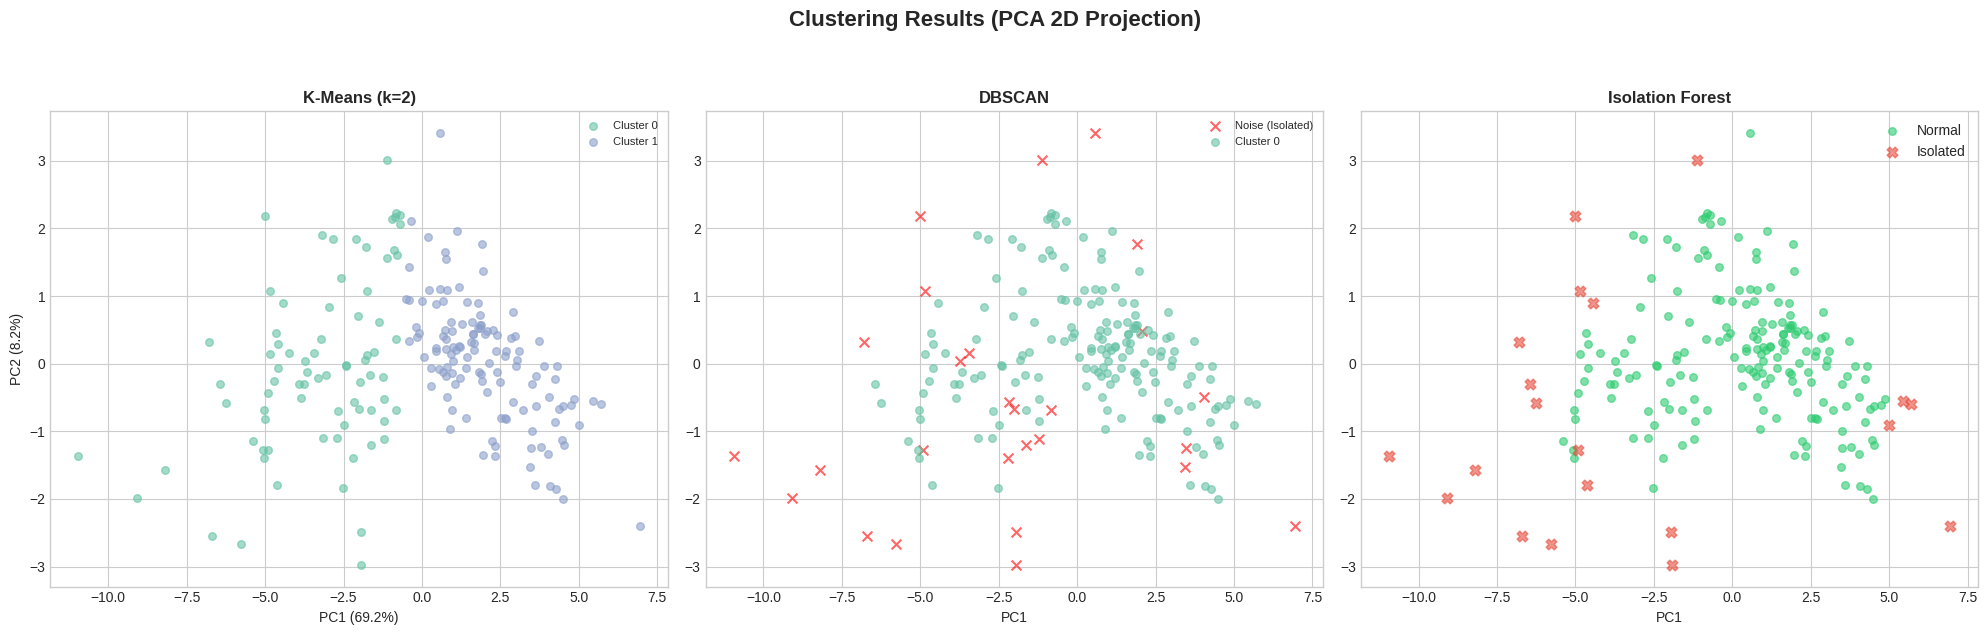

In [13]:
# ============================================================
# EVAL CHART 1: CLUSTER VISUALIZATION (K-Means, PCA 2D)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
cluster_colors = plt.cm.Set2(np.linspace(0, 1, optimal_k + 2))

# K-Means
for c in range(optimal_k):
    mask = student_df['kmeans_cluster'] == c
    axes[0].scatter(student_df.loc[mask, 'pca_1'], student_df.loc[mask, 'pca_2'],
                    alpha=0.6, s=30, color=cluster_colors[c], label=f'Cluster {c}')
axes[0].set_title(f'K-Means (k={optimal_k})', fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# DBSCAN
for c in sorted(student_df['dbscan_cluster'].unique()):
    mask = student_df['dbscan_cluster'] == c
    color = 'red' if c == -1 else cluster_colors[c]
    label = 'Noise (Isolated)' if c == -1 else f'Cluster {c}'
    axes[1].scatter(student_df.loc[mask, 'pca_1'], student_df.loc[mask, 'pca_2'],
                    alpha=0.6, s=30 if c != -1 else 50, color=color, label=label,
                    marker='o' if c != -1 else 'x')
axes[1].set_title('DBSCAN', fontweight='bold')
axes[1].legend(fontsize=8)
axes[1].set_xlabel(f'PC1')

# Isolation Forest
for val, color, label in [(0, '#2ecc71', 'Normal'), (1, '#e74c3c', 'Isolated')]:
    mask = student_df['is_isolated'] == val
    axes[2].scatter(student_df.loc[mask, 'pca_1'], student_df.loc[mask, 'pca_2'],
                    alpha=0.6, s=30 if val == 0 else 60, color=color, label=label,
                    marker='o' if val == 0 else 'X')
axes[2].set_title('Isolation Forest', fontweight='bold')
axes[2].legend()
axes[2].set_xlabel(f'PC1')

fig.suptitle('Clustering Results (PCA 2D Projection)', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('c6_chart4_cluster_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

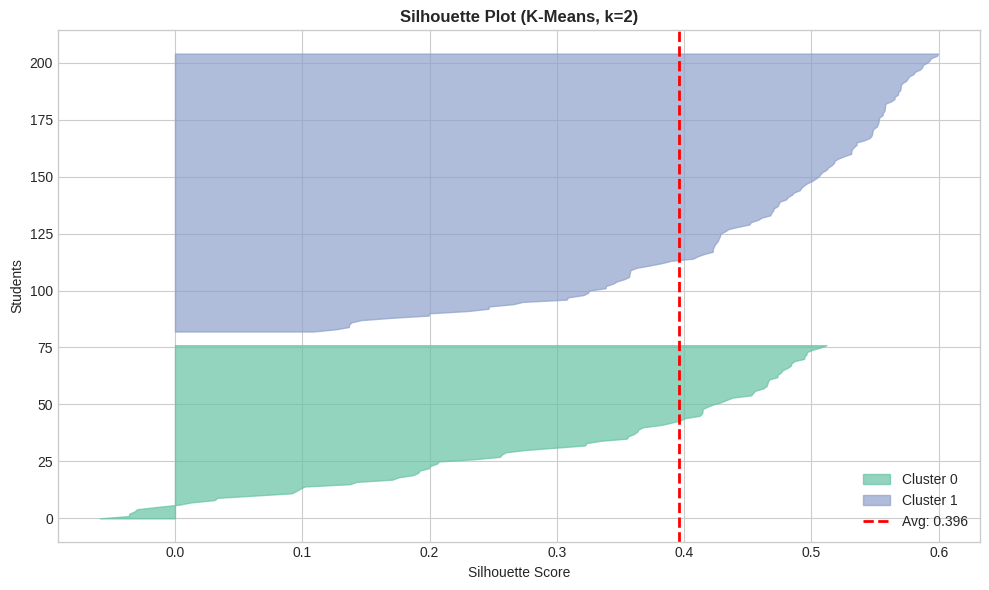

In [14]:
# ============================================================
# EVAL CHART 2: SILHOUETTE PLOT
# ============================================================
sil_values = silhouette_samples(X_scaled, student_df['kmeans_cluster'])
student_df['silhouette'] = sil_values

fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 0
for c in range(optimal_k):
    cluster_sil = np.sort(sil_values[student_df['kmeans_cluster'] == c])
    y_upper = y_lower + len(cluster_sil)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil,
                     alpha=0.7, color=cluster_colors[c], label=f'Cluster {c}')
    y_lower = y_upper + 5

avg_sil = silhouette_score(X_scaled, student_df['kmeans_cluster'])
ax.axvline(avg_sil, color='red', linestyle='--', linewidth=2, label=f'Avg: {avg_sil:.3f}')
ax.set_title(f'Silhouette Plot (K-Means, k={optimal_k})', fontweight='bold')
ax.set_xlabel('Silhouette Score')
ax.set_ylabel('Students')
ax.legend()
plt.tight_layout()
plt.savefig('c6_chart5_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

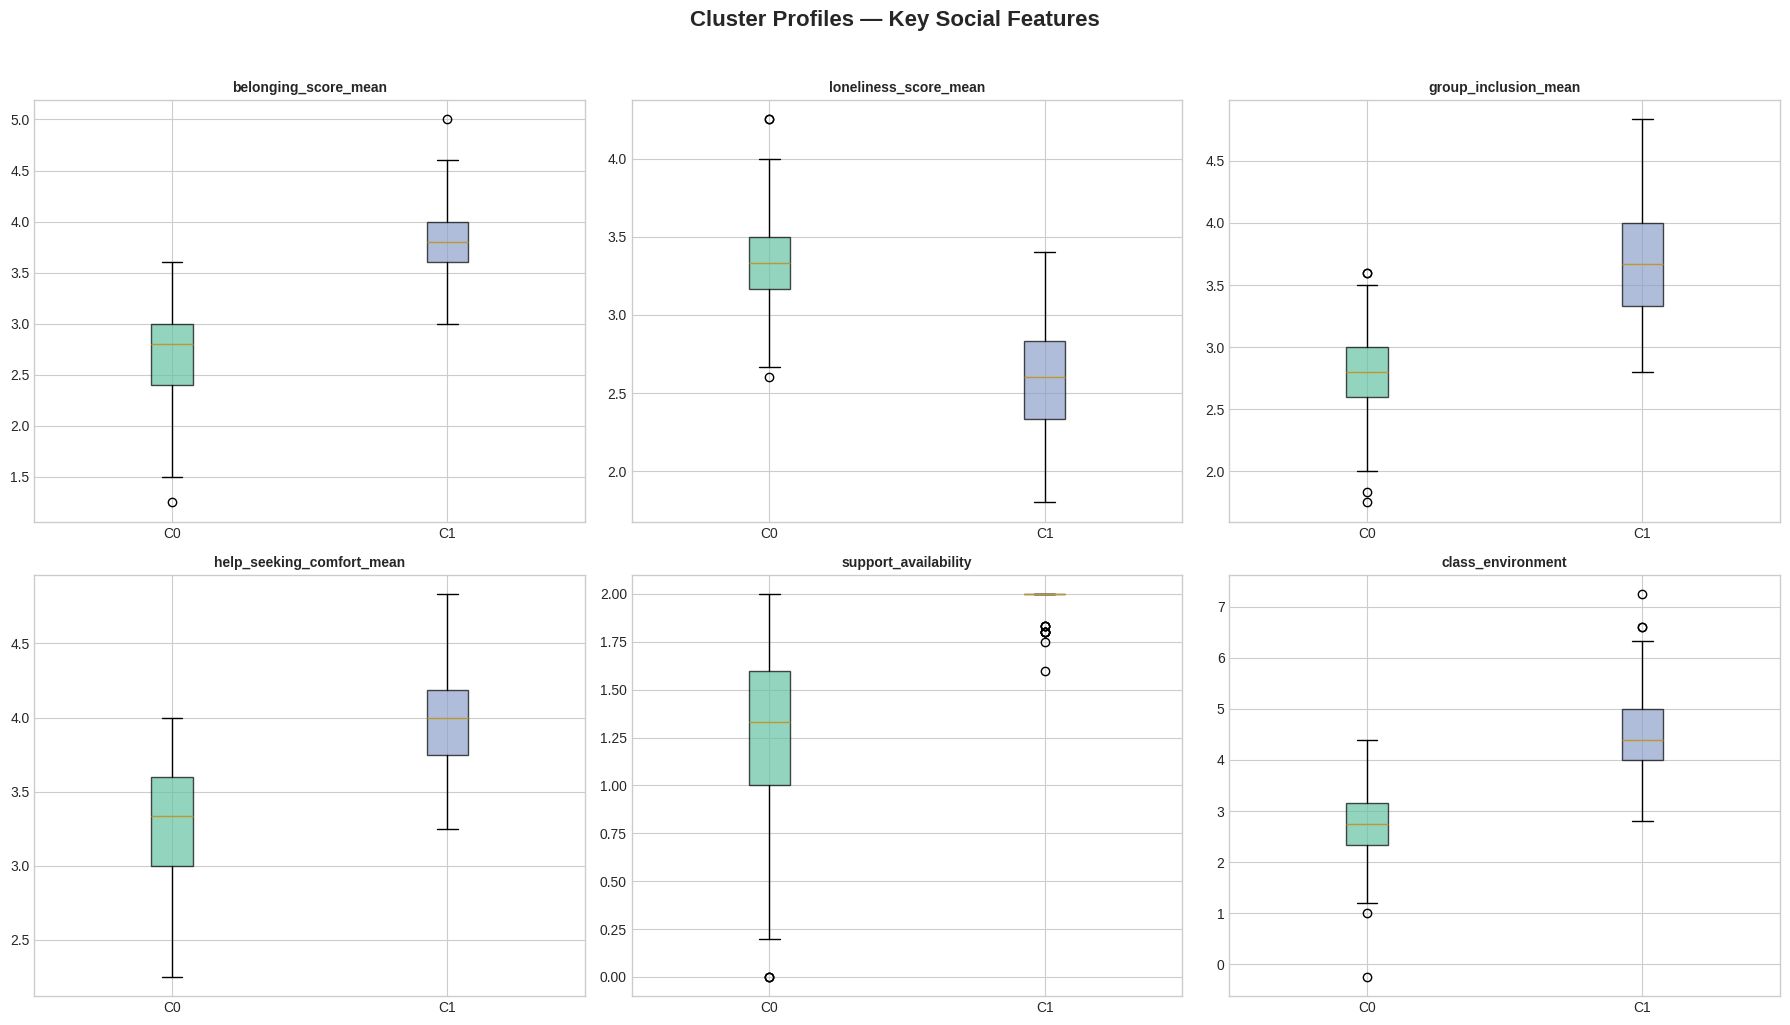

In [15]:
# ============================================================
# EVAL CHART 3: CLUSTER PROFILES (Radar/Box)
# ============================================================
profile_features = ['belonging_score_mean', 'loneliness_score_mean', 'group_inclusion_mean',
                    'help_seeking_comfort_mean', 'support_availability', 'class_environment']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(profile_features):
    data = [student_df[student_df['kmeans_cluster'] == c][feat].values for c in range(optimal_k)]
    bp = axes[i].boxplot(data, labels=[f'C{c}' for c in range(optimal_k)], patch_artist=True)
    for patch, color in zip(bp['boxes'], cluster_colors):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    axes[i].set_title(feat, fontweight='bold', fontsize=10)

fig.suptitle('Cluster Profiles — Key Social Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c6_chart6_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

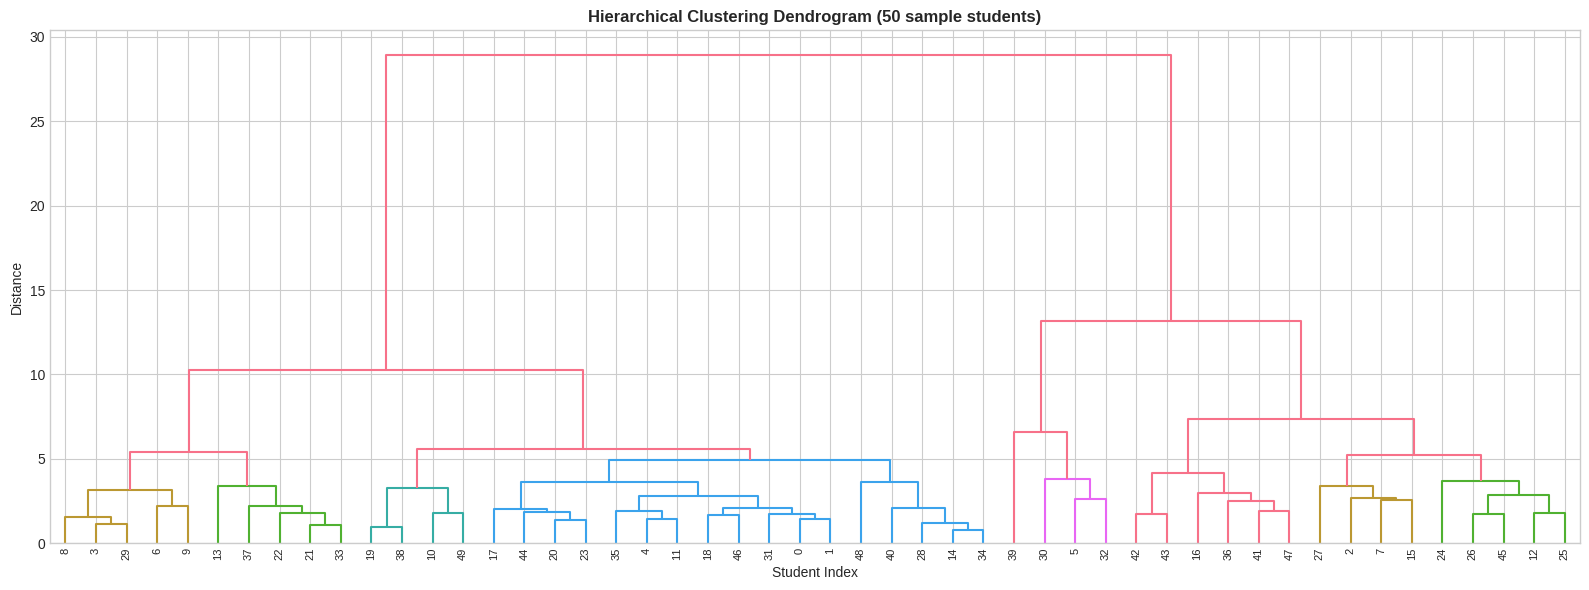

In [16]:
# ============================================================
# EVAL CHART 4: DENDROGRAM (Hierarchical)
# ============================================================
fig, ax = plt.subplots(figsize=(16, 6))
linked = linkage(X_scaled.values[:50], method='ward')  # Sample for readability
dendrogram(linked, ax=ax, leaf_font_size=8, color_threshold=5)
ax.set_title('Hierarchical Clustering Dendrogram (50 sample students)', fontweight='bold')
ax.set_xlabel('Student Index')
ax.set_ylabel('Distance')
plt.tight_layout()
plt.savefig('c6_chart7_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

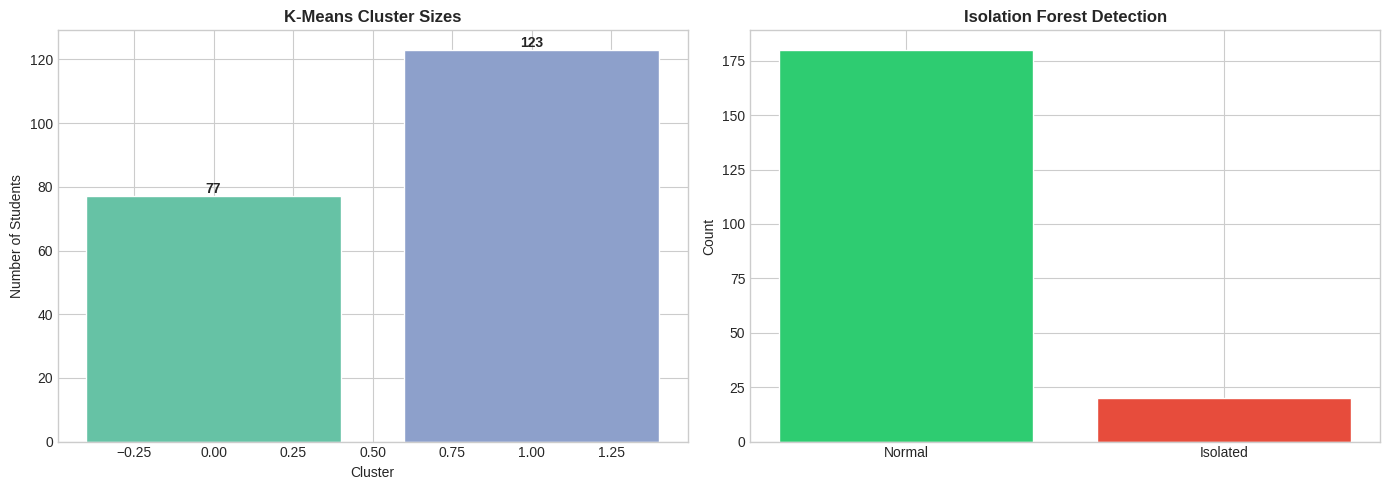

In [17]:
# ============================================================
# EVAL CHART 5: CLUSTER SIZES
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means cluster sizes
km_sizes = student_df['kmeans_cluster'].value_counts().sort_index()
axes[0].bar(km_sizes.index, km_sizes.values, color=[cluster_colors[i] for i in km_sizes.index], edgecolor='white')
for i, (idx, val) in enumerate(km_sizes.items()):
    axes[0].text(idx, val + 1, str(val), ha='center', fontweight='bold')
axes[0].set_title('K-Means Cluster Sizes', fontweight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Number of Students')

# Isolation detection
iso_counts = student_df['is_isolated'].value_counts()
axes[1].bar(['Normal', 'Isolated'], [iso_counts.get(0, 0), iso_counts.get(1, 0)],
            color=['#2ecc71', '#e74c3c'], edgecolor='white')
axes[1].set_title('Isolation Forest Detection', fontweight='bold')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('c6_chart8_cluster_sizes.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 7: Cluster Labeling & Group Recommendations

In [18]:
# ============================================================
# SECTION 7: ASSIGN MEANINGFUL LABELS & RECOMMENDATIONS
# ============================================================
print("\n" + "=" * 60)
print("SECTION 7: CLUSTER LABELING & RECOMMENDATIONS")
print("=" * 60)

# Label clusters based on their mean belonging and loneliness scores
cluster_summary = student_df.groupby('kmeans_cluster')[
    ['belonging_score_mean', 'loneliness_score_mean', 'group_inclusion_mean',
     'support_availability', 'isolation_index']
].mean().round(2)

print("\n--- Cluster Summary ---")
print(cluster_summary)

# Auto-label based on isolation_index
def label_cluster(row):
    if row['isolation_index'] > 7:
        return 'At-Risk / Isolated'
    elif row['isolation_index'] > 5:
        return 'Moderately Connected'
    else:
        return 'Well-Connected'

cluster_labels = cluster_summary.apply(label_cluster, axis=1)
student_df['social_group'] = student_df['kmeans_cluster'].map(cluster_labels)

print("\n--- Social Group Distribution ---")
print(student_df['social_group'].value_counts())

# --- Recommendations per group ---
RECOMMENDATIONS = {
    'At-Risk / Isolated': [
        'Recommend participation in structured group activities (study groups, clubs)',
        'Suggest joining a peer mentoring program',
        'Consider teacher-led small group interactions',
        'Encourage participation in team-based assignments',
    ],
    'Moderately Connected': [
        'Encourage deeper engagement in existing group activities',
        'Suggest trying a new extracurricular activity',
        'Support maintaining current social connections',
    ],
    'Well-Connected': [
        'Continue current social engagement patterns',
        'Consider taking on peer leadership or mentoring roles',
        'Maintain healthy social balance',
    ],
}

print("\n--- Group-Based Recommendations ---")
for group, recs in RECOMMENDATIONS.items():
    count = (student_df['social_group'] == group).sum()
    print(f"\n  [{group}] ({count} students)")
    for rec in recs:
        print(f"    -> {rec}")


SECTION 7: CLUSTER LABELING & RECOMMENDATIONS

--- Cluster Summary ---
                belonging_score_mean  loneliness_score_mean  \
kmeans_cluster                                                
0                               2.69                   3.33   
1                               3.83                   2.56   

                group_inclusion_mean  support_availability  isolation_index  
kmeans_cluster                                                               
0                               2.80                  1.26             7.85  
1                               3.68                  1.98             5.05  

--- Social Group Distribution ---
social_group
Moderately Connected    123
At-Risk / Isolated       77
Name: count, dtype: int64

--- Group-Based Recommendations ---

  [At-Risk / Isolated] (77 students)
    -> Recommend participation in structured group activities (study groups, clubs)
    -> Suggest joining a peer mentoring program
    -> Consider teacher-le

In [19]:
# ============================================================
# ISOLATION RISK FLAGS (Combined)
# ============================================================
# Combine Isolation Forest + cluster label for robust flagging
student_df['isolation_risk_flag'] = (
    (student_df['is_isolated'] == 1) |
    (student_df['social_group'] == 'At-Risk / Isolated')
).astype(int)

n_flagged = student_df['isolation_risk_flag'].sum()
print(f"\n--- Isolation Risk Flag ---")
print(f"Total flagged: {n_flagged} ({n_flagged/len(student_df)*100:.1f}%)")

# Show flagged students
flagged = student_df[student_df['isolation_risk_flag'] == 1][
    ['student_id', 'belonging_score_mean', 'loneliness_score_mean',
     'group_inclusion_mean', 'isolation_index', 'social_group']
].head(10)
print(f"\nSample flagged students:")
print(flagged.to_string(index=False))


--- Isolation Risk Flag ---
Total flagged: 81 (40.5%)

Sample flagged students:
student_id  belonging_score_mean  loneliness_score_mean  group_inclusion_mean  isolation_index         social_group
      S003              2.800000               3.400000              2.800000         7.800000   At-Risk / Isolated
      S006              2.333333               3.333333              2.833333         8.166667   At-Risk / Isolated
      S008              3.000000               3.250000              2.750000         7.500000   At-Risk / Isolated
      S009              4.400000               1.800000              4.000000         3.400000 Moderately Connected
      S010              4.600000               1.800000              4.600000         2.600000 Moderately Connected
      S013              2.600000               3.200000              3.400000         7.200000   At-Risk / Isolated
      S017              2.333333               3.666667              2.333333         9.000000   At-Risk / 

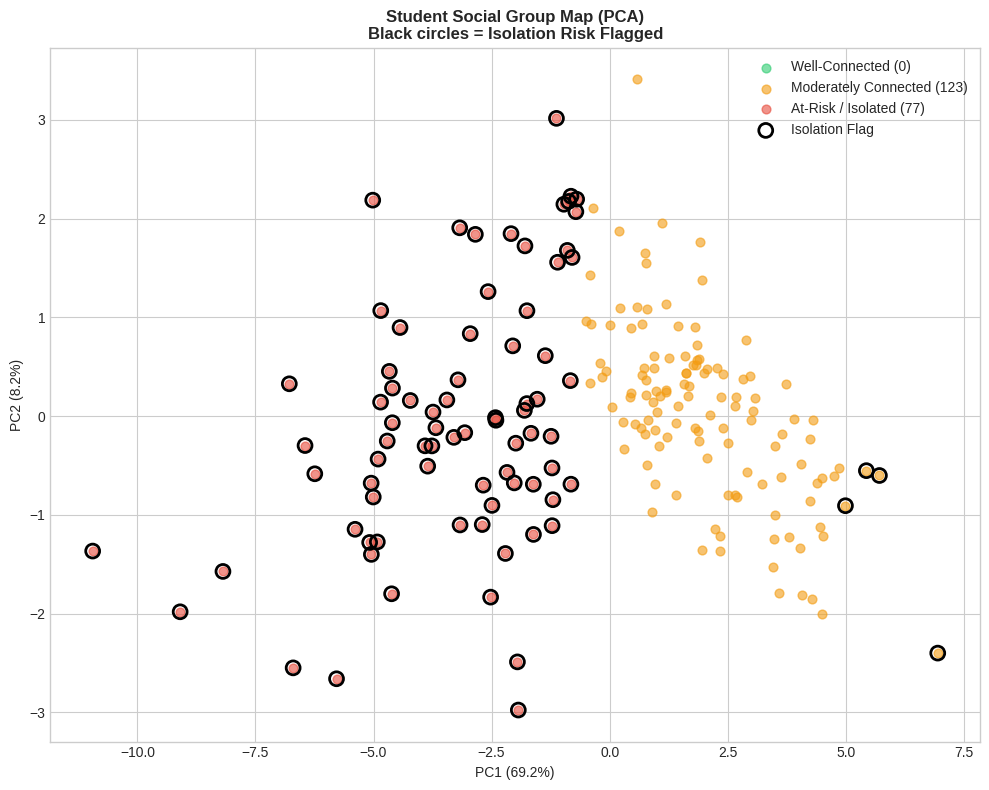

In [20]:
# ============================================================
# FINAL VISUALIZATION: SOCIAL GROUP MAP
# ============================================================
fig, ax = plt.subplots(figsize=(10, 8))
group_colors = {'Well-Connected': '#2ecc71', 'Moderately Connected': '#f39c12', 'At-Risk / Isolated': '#e74c3c'}

for group, color in group_colors.items():
    mask = student_df['social_group'] == group
    ax.scatter(student_df.loc[mask, 'pca_1'], student_df.loc[mask, 'pca_2'],
               alpha=0.6, s=40, color=color, label=f'{group} ({mask.sum()})')

# Highlight isolation-flagged
flagged_mask = student_df['isolation_risk_flag'] == 1
ax.scatter(student_df.loc[flagged_mask, 'pca_1'], student_df.loc[flagged_mask, 'pca_2'],
           facecolors='none', edgecolors='black', s=100, linewidths=2, label='Isolation Flag', zorder=5)

ax.set_title('Student Social Group Map (PCA)\nBlack circles = Isolation Risk Flagged', fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.legend(loc='best')
plt.tight_layout()
plt.savefig('c6_chart9_social_group_map.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 8: Metrics Summary & Export

In [21]:
print("\n" + "=" * 70)
print("CLUSTERING EVALUATION METRICS")
print("=" * 70)

km_labels = student_df['kmeans_cluster']
agg_labels = student_df['agg_cluster']

metrics = {
    'K-Means': {
        'Silhouette': silhouette_score(X_scaled, km_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, km_labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, km_labels),
        'n_clusters': optimal_k,
    },
    'Agglomerative': {
        'Silhouette': silhouette_score(X_scaled, agg_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, agg_labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, agg_labels),
        'n_clusters': optimal_k,
    },
}

# DBSCAN only if it found real clusters
valid_dbscan = student_df['dbscan_cluster'] != -1
if valid_dbscan.sum() > 10 and student_df.loc[valid_dbscan, 'dbscan_cluster'].nunique() > 1:
    metrics['DBSCAN'] = {
        'Silhouette': silhouette_score(X_scaled[valid_dbscan], student_df.loc[valid_dbscan, 'dbscan_cluster']),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled[valid_dbscan], student_df.loc[valid_dbscan, 'dbscan_cluster']),
        'Davies-Bouldin': davies_bouldin_score(X_scaled[valid_dbscan], student_df.loc[valid_dbscan, 'dbscan_cluster']),
        'n_clusters': student_df.loc[valid_dbscan, 'dbscan_cluster'].nunique(),
    }

metrics_df = pd.DataFrame(metrics).T
print(metrics_df.round(4).to_string())

# Export
student_df.to_csv('c3_student_social_profiles.csv', index=False)
metrics_df.to_csv('clustering_results.csv')
joblib.dump(kmeans, 'best_social_clustering_model.pkl')
joblib.dump(scaler, 'social_scaler.pkl')

print(f"\nProfiles saved: c3_student_social_profiles.csv")
print(f"Metrics saved: clustering_results.csv")
print(f"Model saved: best_social_clustering_model.pkl")

print("\n" + "=" * 60)
print("COLAB 6 COMPLETE: Social Peer Matching & Isolation Detection!")
print("=" * 60)
print("\nKey Outputs:")
print(f"  - {optimal_k} social groups identified")
print(f"  - {n_flagged} students flagged for isolation risk")
print(f"  - Group-based recommendations generated (NO peer identification)")


CLUSTERING EVALUATION METRICS
               Silhouette  Calinski-Harabasz  Davies-Bouldin  n_clusters
K-Means            0.3959           176.7012          0.9818         2.0
Agglomerative      0.4003           169.1820          0.9620         2.0

Profiles saved: c3_student_social_profiles.csv
Metrics saved: clustering_results.csv
Model saved: best_social_clustering_model.pkl

COLAB 6 COMPLETE: Social Peer Matching & Isolation Detection!

Key Outputs:
  - 2 social groups identified
  - 81 students flagged for isolation risk
  - Group-based recommendations generated (NO peer identification)
